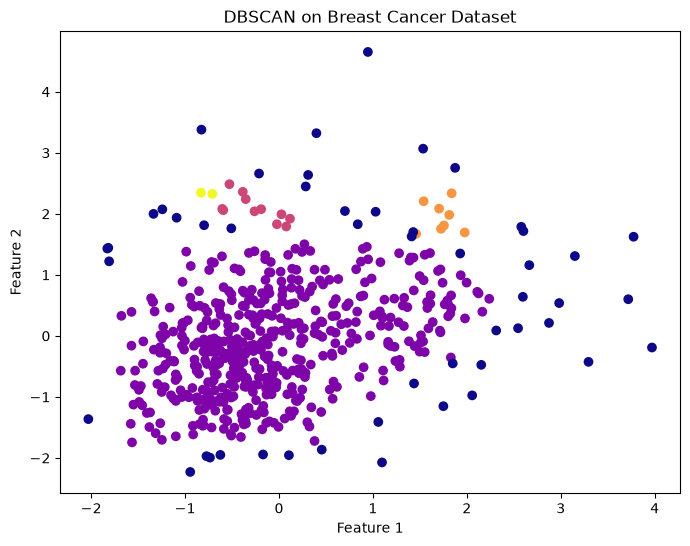

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data[:, :2]

X = StandardScaler().fit_transform(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X)

plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=labels, cmap="plasma")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN on Breast Cancer Dataset")
plt.show()

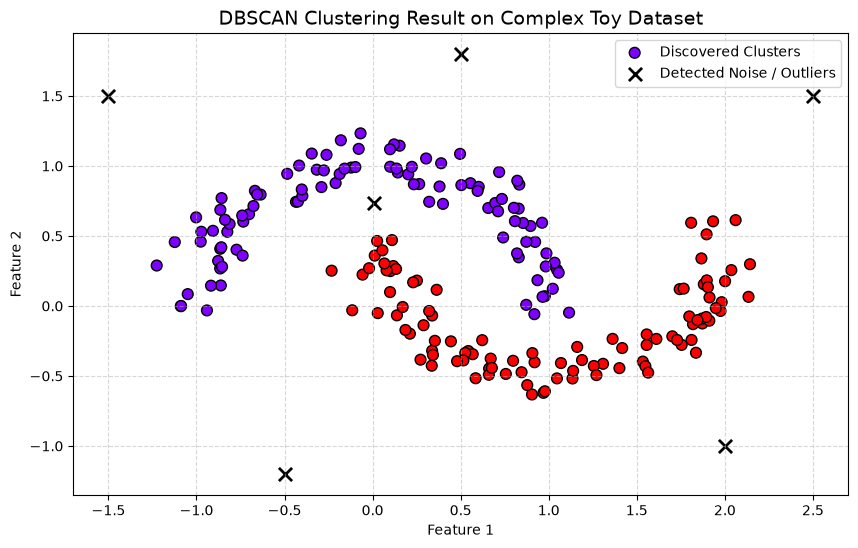

Successfully identified 2 clusters.
Successfully identified and isolated 6 noise points.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# 1. Create a toy dataset with two crescent moons and added random noise
X, y = make_moons(n_samples=200, noise=0.1, random_state=42)

# Manually inject 5 extreme outlier/noise points into the dataset
noise_points = np.array([[-1.5, 1.5], [2.0, -1.0], [0.5, 1.8], [-0.5, -1.2], [2.5, 1.5]])
X = np.vstack([X, noise_points])

# 2. Initialize and fit the DBSCAN algorithm
# eps: radius of the neighborhood circle
# min_samples: minimum points in the circle to call it a dense crowd
dbscan = DBSCAN(eps=0.22, min_samples=5)
cluster_labels = dbscan.fit_predict(X)

# 3. Plot the final clustering results
plt.figure(figsize=(10, 6))

# Identify core, border, and noise masks
# In scikit-learn, DBSCAN labels noise points strictly as -1
is_noise = (cluster_labels == -1)
is_cluster = ~is_noise

# Plot the valid discovered clusters using a color map
scatter_clusters = plt.scatter(
    X[is_cluster, 0], X[is_cluster, 1], 
    c=cluster_labels[is_cluster], cmap='rainbow', 
    s=60, edgecolors='k', label='Discovered Clusters'
)

# Plot the identified noise points separately as black 'X' marks
scatter_noise = plt.scatter(
    X[is_noise, 0], X[is_noise, 1], 
    color='black', marker='x', 
    s=90, linewidths=2, label='Detected Noise / Outliers'
)

plt.title("DBSCAN Clustering Result on Complex Toy Dataset", fontsize=14)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

# Print out a summary of the clustering execution
unique_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
num_noise = list(cluster_labels).count(-1)
print(f"Successfully identified {unique_clusters} clusters.")
print(f"Successfully identified and isolated {num_noise} noise points.")
